# Place-like fields (Fig. 7)

Reproduces Fig. 7 (Appendix H): the rate maps and the spatial similarity function of a
population whose generator eigenvalues are drawn from a Gaussian instead of placed on a ring.

Eq. 4 is a discrete inverse Fourier transform of the eigenvalue spectrum, so the eigenvalue
distribution sets the similarity function. Appendix I draws the eigenvalues from
$\mathcal{N}(0, 2\sigma^2)$ for a similarity $C(\Delta) \approx e^{-\sigma^2\Delta^2}$, and
Appendix H applies this to space. The units have heterogeneous, localized, place-like fields.
The paper calls this a proof of concept: it does not capture the sparsity, overdispersion or
multiple fields of recorded place cells.

The `scale` of `gaussian_eigenvalues` is the standard deviation of the eigenvalues, so
$\text{scale}^2 = 2\sigma^2$ and $C(\Delta) \approx e^{-\text{scale}^2\Delta^2/2}$. The default
$\text{scale} = \sqrt{2}$ is the $\mathcal{N}(0, 2)$ of Appendix H with $\sigma = 1$. The last
cell checks the similarity against Eq. 4 and against this Gaussian.

$N = 256$ and $\mathcal{N}(0, 2)$ are Appendix H. The printed panels were drawn in an arena of
half-width 1.5, which is used here, from eigenvalues and a mixing matrix $R$ that were not
recorded, so the fields and the ripple of the similarity differ from the print. `SEED` fixes
the spectrum, $R$ and the position sampling.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.analysis import batch_inference, compute_ratemaps, compute_similarity
from expmap.generators import block_diag_skew, build_generators, gaussian_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

N = 256
SCALE = np.sqrt(2)  # standard deviation of the eigenvalues, N(0, 2)
ARENA_SIZE = 1.5
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# x and y are drawn independently, so the wavevectors scatter over the plane instead of
# sitting on a ring. The two spectra share the 2 x 2 blocks, so the generators still commute.
ev_x = gaussian_eigenvalues(N, scale=SCALE, seed=SEED)
ev_y = gaussian_eigenvalues(N, scale=SCALE, seed=SEED + 1)
sigma_x = block_diag_skew(ev_x)
sigma_y = block_diag_skew(ev_y)

R = random_orthogonal_matrix(N, seed=SEED)
p0 = starting_state(R)
Gx, Gy = build_generators(sigma_x, sigma_y, R)
model = ExponentialMap(Gx, Gy)

assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "generators must commute"
assert torch.allclose(Gx, -Gx.T, atol=1e-6), "generators must be skew-symmetric"

print(f"N = {len(Gx)} units")

N = 256 units


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)

p = batch_inference(model, r_batch, p0, progress=False)
r = np.concatenate(r_batch)

# Skew-symmetric generators give an equinorm representation whatever the spectrum.
norms = np.linalg.norm(p, axis=1)
print(f"||p|| = {norms.mean():.6f} +/- {norms.std():.2e}")

||p|| = 1.000000 +/- 5.04e-07


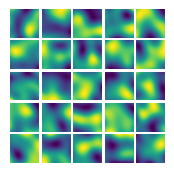

In [4]:
# Fig. 7, left.
ratemaps = compute_ratemaps(r[:, 0], r[:, 1], p, bins=BINS)

fig, _ = ratemap_collage(ratemaps, rows=5, cols=5, figsize=(2, 2))
fig.savefig(FIGURE_DIR / "pc_ratemaps.svg", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "pc_ratemaps.png", dpi=300, transparent=True, bbox_inches="tight")

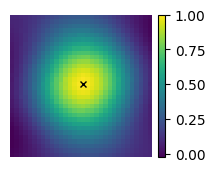

In [5]:
# Fig. 7, right: the similarity relative to the center bin.
a = BINS // 2
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2
extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)

plt.figure(figsize=(2, 2))
plt.imshow(similarity.T, vmax=1, extent=extent, origin="lower")
plt.plot(centers[a], centers[a], "kx", markersize=5)
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis("off")
plt.savefig(FIGURE_DIR / "pc_similarity.svg", dpi=300, transparent=True, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "pc_similarity.png", dpi=300, transparent=True, bbox_inches="tight")

## Checks against Eq. 4 and the Gaussian

Eq. 4 is exact for any spectrum, so the similarity evaluated at the bin centers agrees with it
to float precision. The Gaussian is a Monte Carlo estimate of the Fourier integral over
$N/2 = 128$ eigenvalues (App. I), so it holds to about $1/\sqrt{N/2}$, and the ripple away
from the center is that finite-$N$ error.

max |empirical - Eq. 4|          = 1.45e-06
rms |empirical - Gaussian|       = 0.0563
Monte Carlo error 1/sqrt(N/2)    = 0.0884


Text(0, 0.5, 'y')

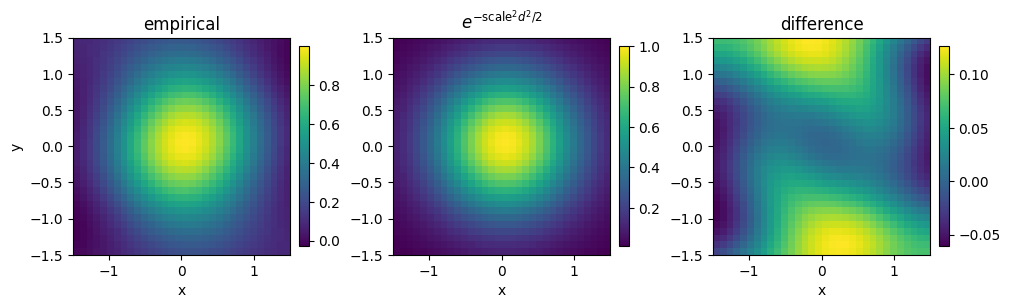

In [6]:
X, Y = np.meshgrid(centers, centers, indexing="ij")
grid_positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    p_grid = model(grid_positions, p0).numpy()

empirical = compute_similarity(p_grid.T.reshape(N, BINS, BINS), ref_bin=(a, a))

dx = centers[:, None] - centers[a]
dy = centers[None, :] - centers[a]
eq4 = sum((2 / N) * np.cos(ev_x[i] * dx + ev_y[i] * dy) for i in range(N // 2))
gaussian = np.exp(-(SCALE**2) * (dx**2 + dy**2) / 2)

print(f"max |empirical - Eq. 4|          = {np.nanmax(np.abs(empirical - eq4)):.2e}")
print(f"rms |empirical - Gaussian|       = {np.sqrt(np.mean((empirical - gaussian) ** 2)):.4f}")
print(f"Monte Carlo error 1/sqrt(N/2)    = {1 / np.sqrt(N // 2):.4f}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), layout="constrained")
for ax, img, title in zip(
    axs,
    [empirical.T, gaussian.T, (empirical - gaussian).T],
    ["empirical", r"$e^{-\mathrm{scale}^2 d^2 / 2}$", "difference"],
):
    im = ax.imshow(img, extent=extent, origin="lower")
    ax.set_title(title)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")